In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import re
import string

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Gensim
import gensim
import gensim.corpora as corpora
from gensim.utils import simple_preprocess
from gensim.models import CoherenceModel
from pprint import pprint

# Plotting tools
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Topic Modelling

Topic modeling is an unsupervised learning technique used to extract topics from a large corpus of text automatically. Topics can be defined as the co-occurring terms that are frequently repeating in the text corpus.

Topic modeling is helpful in various tasks such as:

* Clustering documents
* Understanding and summarizing an extensive collection of textual documents
* Retrieving information from an extensive collection of data

In this notebook, I will perform topic modelling using **LDA (Latent Dirichlet Allocation)**.

## Dataset

Here I am using the **Medium Article Dataset** to perform Topic Modelling. The dataset consists of **350 articles** related to **AI, Machine Learning, and Data Science**.


In [2]:
#Exploring Dataset
import pandas as pd 

medium_articles = pd.read_csv("articles.csv")
medium_articles.head()

,author,claps,reading_time,link,title,text
0,Justin Lee,8.3K,11,https://medium.com/swlh/chatbots-were-the-next...,Chatbots were the next big thing: what happene...,"Oh, how the headlines blared:\nChatbots were T..."
1,Conor Dewey,1.4K,7,https://towardsdatascience.com/python-for-data...,Python for Data Science: 8 Concepts You May Ha...,If you’ve ever found yourself looking up the s...
2,William Koehrsen,2.8K,11,https://towardsdatascience.com/automated-featu...,Automated Feature Engineering in Python – Towa...,Machine learning is increasingly moving from h...
3,Gant Laborde,1.3K,7,https://medium.freecodecamp.org/machine-learni...,Machine Learning: how to go from Zero to Hero ...,If your understanding of A.I. and Machine Lear...
4,Emmanuel Ameisen,935,11,https://blog.insightdatascience.com/reinforcem...,Reinforcement Learning from scratch – Insight ...,Want to learn about applied Artificial Intelli...


Total Number of unique authors : 182


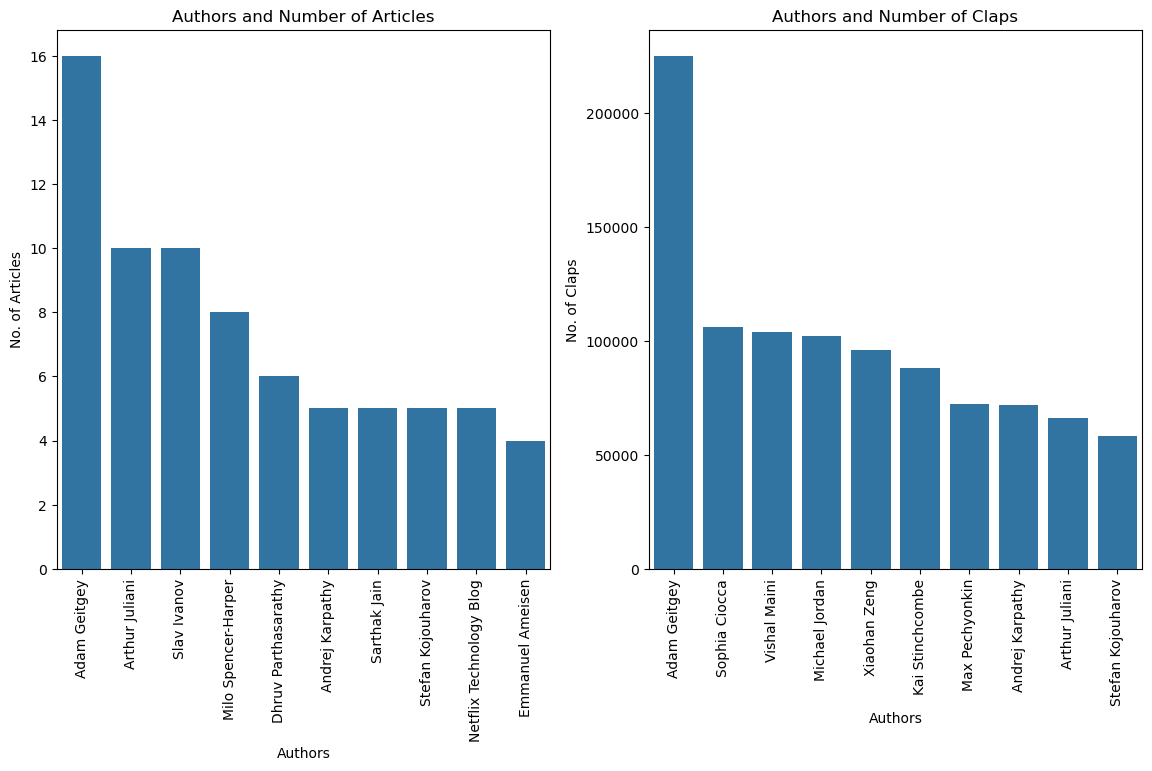

In [3]:
article_text = medium_articles.text
# visualise first article print few words from it
#print("First 1000 words in first article are : \n",article_text[0][:1000])

#total number of author
print(f"Total Number of unique authors : {len(medium_articles.author.unique())}")

#counting the articles of different authors (already sorted high -> low)
article_counts = medium_articles.author.value_counts().to_dict()

#plot histogram of top 10 authors and their article counts
plt.figure(figsize=(14,7))
plt.subplot(1, 2, 1)
sns.barplot(x = list(article_counts.keys())[:10],y=list(article_counts.values())[:10])
plt.title("Authors and Number of Articles")
plt.xlabel("Authors")
plt.ylabel("No. of Articles")
plt.xticks(rotation = 90) 


#converting claps like "1.4K" to numbers
def convert_to_num(clap_count):
    clap_count = str(clap_count)   # safe if the cell is run twice
    if "K" in clap_count:
        if "." in clap_count:
            clap_count = re.sub("\.","",clap_count[:-1])+"00"
        else:
            clap_count = clap_count[:-1]+"000"
    return(int(clap_count))

medium_articles.claps = medium_articles.claps.apply(convert_to_num)

#total number of claps for each author (sorted high -> low)
clap_counts = medium_articles.groupby("author")["claps"].sum().sort_values(ascending=False).to_dict()

#plot histogram of top 10 authors and their clap counts
plt.subplot(1, 2, 2)
sns.barplot(x = list(clap_counts.keys())[:10],y=list(clap_counts.values())[:10])
plt.title("Authors and Number of Claps")
plt.xlabel("Authors")
plt.ylabel("No. of Claps")
plt.xticks(rotation = 90) 
plt.show()

The above graphs show that Adam Geitgey has written most articles and has the highest number of claps. But when it comes to the 2nd, 3rd positions, the author's name is not the same in the graphs. It shows that either the reach of articles or the quality of articles is inadequate for the authors.

Here, we can see that Adam Geitgey has written highest number of articles.

# Preprocessing Text Data

In [4]:
#lowercase the articles 
medium_articles.text = medium_articles.text.apply(lambda t : t.lower())

### Expanding contractions: 
Contractions are the shortened form of the words like it's, hasn't. We expand them for better analysis of our text data. 

In [5]:
# Dictionary of English Contractions
contractions_dict = { "ain't": "are not","'s":" is","aren't": "are not",
                     "can't": "cannot","can't've": "cannot have",
                     "'cause": "because","could've": "could have","couldn't": "could not",
                     "couldn't've": "could not have", "didn't": "did not","doesn't": "does not",
                     "don't": "do not","hadn't": "had not","hadn't've": "had not have",
                     "hasn't": "has not","haven't": "have not","he'd": "he would",
                     "he'd've": "he would have","he'll": "he will", "he'll've": "he will have",
                     "how'd": "how did","how'd'y": "how do you","how'll": "how will",
                     "i'd": "i would", "i'd've": "i would have","i'll": "i will",
                     "i'll've": "i will have","i'm": "i am","i've": "i have", "isn't": "is not",
                     "it'd": "it would","it'd've": "it would have","it'll": "it will",
                     "it'll've": "it will have", "let's": "let us","ma'am": "madam",
                     "mayn't": "may not","might've": "might have","mightn't": "might not", 
                     "mightn't've": "might not have","must've": "must have","mustn't": "must not",
                     "mustn't've": "must not have", "needn't": "need not",
                     "needn't've": "need not have","o'clock": "of the clock","oughtn't": "ought not",
                     "oughtn't've": "ought not have","shan't": "shall not","sha'n't": "shall not",
                     "shan't've": "shall not have","she'd": "she would","she'd've": "she would have",
                     "she'll": "she will", "she'll've": "she will have","should've": "should have",
                     "shouldn't": "should not", "shouldn't've": "should not have","so've": "so have",
                     "that'd": "that would","that'd've": "that would have", "there'd": "there would",
                     "there'd've": "there would have", "they'd": "they would",
                     "they'd've": "they would have","they'll": "they will",
                     "they'll've": "they will have", "they're": "they are","they've": "they have",
                     "to've": "to have","wasn't": "was not","we'd": "we would",
                     "we'd've": "we would have","we'll": "we will","we'll've": "we will have",
                     "we're": "we are","we've": "we have", "weren't": "were not","what'll": "what will",
                     "what'll've": "what will have","what're": "what are", "what've": "what have",
                     "when've": "when have","where'd": "where did", "where've": "where have",
                     "who'll": "who will","who'll've": "who will have","who've": "who have",
                     "why've": "why have","will've": "will have","won't": "will not",
                     "won't've": "will not have", "would've": "would have","wouldn't": "would not",
                     "wouldn't've": "would not have","y'all": "you all", "y'all'd": "you all would",
                     "y'all'd've": "you all would have","y'all're": "you all are",
                     "y'all've": "you all have", "you'd": "you would","you'd've": "you would have",
                     "you'll": "you will","you'll've": "you will have", "you're": "you are",
                     "you've": "you have"}

# Regular expression for finding contractions (longest first so "can't've" wins over "can't")
contractions_re=re.compile(r"(%s)(?!\w)" % '|'.join(sorted(map(re.escape, contractions_dict.keys()), key=len, reverse=True)))

# Function for expanding contractions
def expand_contractions(text,contractions_dict=contractions_dict):
    text = text.replace("’", "'")   # curly -> straight apostrophe so contractions match
    def replace(match):
        return contractions_dict[match.group(0)]
    return contractions_re.sub(replace, text)

# Expanding Contractions in the text data
medium_articles.text = medium_articles.text.apply(lambda x:expand_contractions(x))

### Removing Stopwords and Puctuations: 
Stopwords are the words that are highly occurred in a language; they do not add any significance to the sentence. "a," "an," "the," "in" are some examples of stopwords. So we generally ignore stop words during our NLP task. In some NLP tasks, stop words are also important, but stopwords are unnecessary for topic modeling. We also remove punctuation marks because they are also unnecessary and do not contribute anything

In [6]:
print(stopwords.words('english'))

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

In [7]:
print(f"These are the pucntions which string.punctuation consist :  {string.punctuation}")

These are the pucntions which string.punctuation consist :  !"#$%&'()*+,-./:;<=>?@[\]^_`{|}~


In [8]:
stop_words = set(stopwords.words('english')) 

def remove_stopwords(article):
    "Return the articel after remvoing stopwords"
    article_tokens = word_tokenize(article) 
    filtered_article = [word for word in article_tokens if not word in stop_words] 
    return " ".join(filtered_article)


#removing stopwords
medium_articles.text = medium_articles.text.apply(remove_stopwords)

#removing Punctuations 
medium_articles.text = medium_articles.text.apply(lambda x: re.sub('[%s]' % re.escape(string.punctuation), '', x))

#removing digits
medium_articles.text = medium_articles.text.apply(lambda x: re.sub('\w*\d\w*','', x))

medium_articles.text[50]

'upd  april      scikit flow merged tensorflow since version  called tensorflow learn tflearn  google released machine learning framework called tensorflow taking world storm   stars github  lot publicity general excitement ai researchers   use something regular problem data scientist may   ai researcher — build interesting problems time   reasonable question  data scientist  already number tools toolbox  r  scikit learn  etc   care yet another framework  answer two part  let us start simple example — take titanic dataset kaggle  first  make sure installed tensorflow scikit learn helpful libs  including scikit flow simplifying lot work tensorflow  get dataset code http  githubcomilblackdragontfexamples quick look data  use ipython ipython notebook ease interactive exploration   let us test predict survived class  based float variables scikit learn  separate dataset features target  fill na data zeros build logistic regression  predicting training data gives us measure accuracy  cause p

There are still some marks like quotation marks, hypen and apostrophe still remaining in the article, we also need to remove them.

In [9]:
def remove_extra_marks(article):
    extra_keys = ["’","—","”","“"]
    article_tokens = word_tokenize(article) 
    filtered_article = [word for word in article_tokens if not word in extra_keys] 
    return " ".join(filtered_article)
    
medium_articles.text = medium_articles.text.apply(remove_extra_marks)

In [10]:
#printing arbitrary example to visulise clean data
medium_articles.text[50]

'upd april scikit flow merged tensorflow since version called tensorflow learn tflearn google released machine learning framework called tensorflow taking world storm stars github lot publicity general excitement ai researchers use something regular problem data scientist may ai researcher build interesting problems time reasonable question data scientist already number tools toolbox r scikit learn etc care yet another framework answer two part let us start simple example take titanic dataset kaggle first make sure installed tensorflow scikit learn helpful libs including scikit flow simplifying lot work tensorflow get dataset code http githubcomilblackdragontfexamples quick look data use ipython ipython notebook ease interactive exploration let us test predict survived class based float variables scikit learn separate dataset features target fill na data zeros build logistic regression predicting training data gives us measure accuracy cause properly evaluate model quality test dataset

### Lemmaztisation: 
Lemmatization process Topic modeling algorithm to avoid making mistakes by converting the word in its root from like lemmatization prevents counting "help", "helps", "helping" as three different words. Stemming can also be used, but it performs the task more forcefully, and sometimes the word loses its meaning, so I prefer lemmatization for the topic modeling task.

Here I am using spacy library to perform the lemmatizaton task.

In [11]:
import spacy
nlp = spacy.load('en_core_web_sm')
print(f""" "helps" after lemmztization :  {nlp("helps")[0].lemma_}""")
print(f""" "helping" after lemmztization :  {nlp("helping")[0].lemma_}""")

 "helps" after lemmztization :  help
 "helping" after lemmztization :  help


In [12]:
def lemmatize(text):
    """Return text after performing the lemmztiztion"""
    doc = nlp(text)
    return  " ".join([token.lemma_ for token in doc])

#lemmatize the articles
medium_articles.text = medium_articles.text.apply(lemmatize)

### Cleaning after lemmatization:
Lemmatization can create new stopwords (e.g. "be", "have") and stray tokens like `'`. So we run one more cleaning pass: remove stopwords again and keep only alphabetic tokens with at least 2 characters.

In [13]:
def clean_after_lemma(text):
    return " ".join([w for w in text.split() if w.isalpha() and len(w) > 1 and w not in stop_words])

medium_articles.text = medium_articles.text.apply(clean_after_lemma)

Now we have finished with all the data preprocessing steps, and let's plot a word cloud to visualize the most frequently used words and see the most commonly occurred word in the articles.

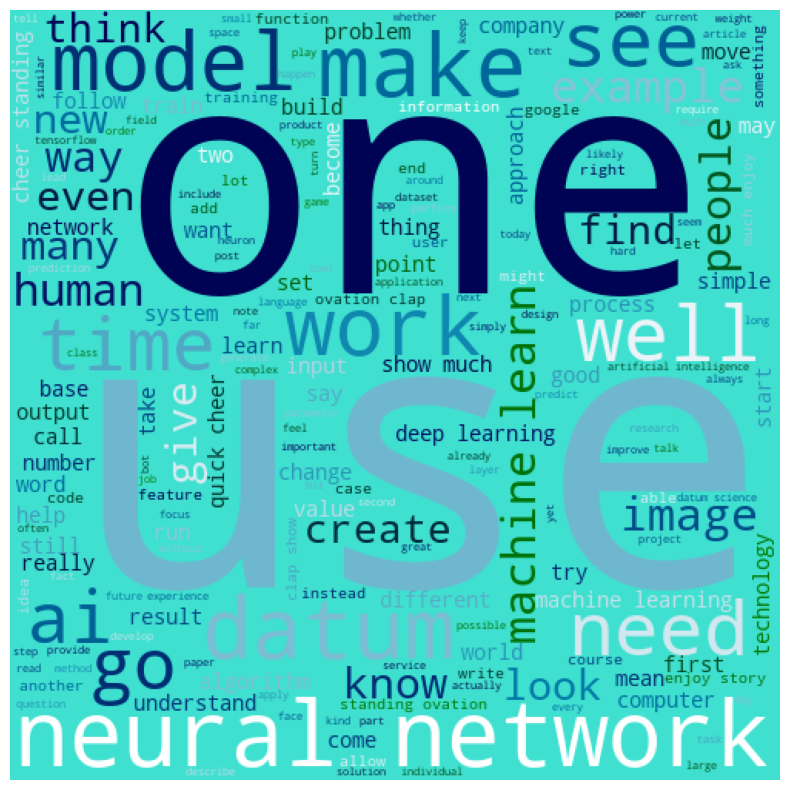

In [14]:
import wordcloud
from wordcloud import WordCloud

#combine all the articles
article_data = ""
for article in medium_articles.text:
    article_data = article_data+" "+article

#ploting the word cloud
plt.figure(figsize=(10, 10))
wordcloud = WordCloud(width = 500, height = 500, background_color='#40E0D0', colormap="ocean",  random_state=10).generate(article_data)
plt.imshow(wordcloud)
plt.axis("off")
plt.show()

## Latent Dirichlet Allocation [LDA]

LDA algorithm is an unsupervised learning algorithm that works on a probabilistic statistical model to discover topics that the document contains automatically.

This algorithm works on certain assumptions. The assumption is that the document was generated by picking a set of topics and picking a set of words for each topic. In other words, we can say that the document is a probability distribution over the latent topics, and topics are probability distribution over the words.

Now let's understand the work methodology of LDA using **Plate Diagram**:

### Plate Diagram of LDA Model

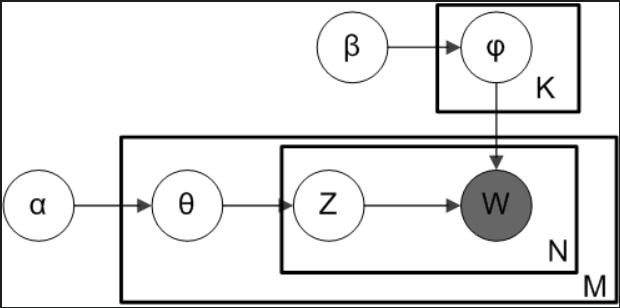

Here, **α** and **β** are two hyperparameters that we have to initialise manually, and they symbolize per topic distribution (**α**) and per topic word distribution (**β**), respectively.

**Z** is the topic for the **N-th word** in document **M**, and **W** is the specific word. We can only see **W** (specific words) in the documents because it is only an observable variable, and all others are latent.

**θ** is the matrix where rows are the documents; columns are topics, and **θ(i,j)** represents the probability of *ith document* containing *jth topic*.

Similarly, **ϕ** is the matrix where rows are the topics; columns are words, and **ϕ(i,j)** represents the probability of *ith topic* containing *jth word*.

According to the distribution of **ϕ**, **K** individual words are generated for the topics.

With the help of this LDA, try to estimate the words that belong to each topic and find the topics in documents accordingly.


In [15]:
#tokenize articles
tokeize_article = medium_articles.text.apply(lambda x : x.split())
id2word = corpora.Dictionary(tokeize_article)

# Drop very rare words (in < 5 articles) and very common words (in > 50% of articles)
id2word.filter_extremes(no_below=5, no_above=0.5)
print("Vocabulary size:", len(id2word))

# Create Corpus
texts = tokeize_article

# Term Document Frequency
corpus = [id2word.doc2bow(text) for text in texts]


#printing 50 words from the text corpus
corpus_example = [[(id2word[id], freq) for id, freq in cp] for cp in corpus[:2]]
corpus_example[0][:50]

Vocabulary size: 4512


[('abruptly', 1),
 ('acceptance', 1),
 ('access', 1),
 ('accident', 1),
 ('accord', 2),
 ('achieve', 2),
 ('advantage', 1),
 ('agenda', 1),
 ('ago', 2),
 ('aim', 1),
 ('alive', 1),
 ('allow', 1),
 ('along', 1),
 ('alternative', 1),
 ('amount', 1),
 ('analyze', 1),
 ('answer', 1),
 ('anticipate', 1),
 ('anyone', 1),
 ('anything', 2),
 ('app', 12),
 ('apply', 1),
 ('approach', 3),
 ('area', 2),
 ('arise', 1),
 ('ask', 1),
 ('aspect', 1),
 ('assumption', 1),
 ('attention', 1),
 ('automate', 2),
 ('available', 1),
 ('average', 1),
 ('away', 2),
 ('back', 3),
 ('basic', 1),
 ('basically', 1),
 ('begin', 2),
 ('behind', 1),
 ('believe', 1),
 ('benefit', 1),
 ('big', 2),
 ('bill', 1),
 ('bit', 2),
 ('black', 1),
 ('bot', 30),
 ('box', 1),
 ('brain', 1),
 ('brand', 2),
 ('break', 1),
 ('brittle', 1)]

In [16]:
# build LDA model for 10 topic
lda_model = gensim.models.ldamodel.LdaModel(corpus=corpus,
                                           id2word=id2word,
                                           num_topics=10, 
                                           random_state=100,
                                           update_every=1,
                                           chunksize=100,
                                           passes=10,
                                           alpha='symmetric',
                                           per_word_topics=True,
                                           eta = 0.6)

In [17]:
# Print the Keyword in the 10 topics
pprint(lda_model.print_topics())
doc_lda = lda_model[corpus]

[(0,
  '0.022*"layer" + 0.021*"feature" + 0.011*"output" + 0.011*"image" + '
  '0.009*"convolution" + 0.008*"pixel" + 0.008*"vector" + 0.007*"architecture" '
  '+ 0.007*"word" + 0.006*"convolutional"'),
 (1,
  '0.019*"course" + 0.012*"word" + 0.009*"python" + 0.008*"week" + '
  '0.007*"language" + 0.007*"teach" + 0.007*"review" + 0.007*"cluster" + '
  '0.007*"video" + 0.007*"google"'),
 (2,
  '0.028*"de" + 0.013*"rcnn" + 0.013*"gpu" + 0.012*"fast" + 0.012*"la" + '
  '0.010*"image" + 0.010*"gtx" + 0.010*"en" + 0.009*"box" + 0.009*"card"'),
 (3,
  '0.010*"really" + 0.009*"interview" + 0.006*"title" + 0.006*"day" + '
  '0.006*"bit" + 0.005*"feel" + 0.005*"question" + 0.005*"novel" + '
  '0.005*"star" + 0.004*"watson"'),
 (4,
  '0.027*"image" + 0.011*"training" + 0.010*"https" + 0.009*"file" + '
  '0.008*"object" + 0.008*"sheet" + 0.008*"cheat" + 0.007*"tensorflow" + '
  '0.006*"keras" + 0.006*"pi"'),
 (5,
  '0.019*"image" + 0.014*"memory" + 0.013*"generate" + 0.009*"training" + '
  '0.008

Each topic is shown as its 10 most important keywords with their weights. For example, `0.008*"action"` means the word "action" has a weight of 0.008 in that topic. Read the keywords of each topic to decide what theme it represents.

### Visualising Topics:

In [18]:
# Visualize the topics
pyLDAvis.enable_notebook()
vis = gensimvis.prepare(lda_model, corpus, id2word)
vis

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
7     -0.025617  0.079921       1        1  31.168094
9      0.140082 -0.064652       2        1  11.377209
1     -0.042328  0.075392       3        1   9.804818
0      0.037110 -0.059538       4        1   8.771624
6      0.149834  0.020660       5        1   7.744345
5     -0.011764 -0.005700       6        1   7.446344
4     -0.049584 -0.042803       7        1   6.931982
2     -0.110280 -0.166922       8        1   6.104864
3     -0.062330  0.082704       9        1   5.329764
8     -0.025125  0.080940      10        1   5.320955, topic_info=           Term         Freq        Total Category  logprob  loglift
1117      image  1184.000000  1184.000000  Default  30.0000  30.0000
258       layer   938.000000   938.000000  Default  29.0000  29.0000
969      neuron   555.000000   555.000000  Default  28.0000  28.0000
899          de   385.000000   385.000000  Default  27.0000  27.0000
692      action   423.000000   423.000000  Default  26.0000  26.0000
...         ...          ...          ...      ...      ...      ...
200      google    37.963626   467.558828  Topic10  -5.7045   0.4226
257       large    36.703926   437.609854  Topic10  -5.7383   0.4551
838   structure    30.842015   175.388577  Topic10  -5.9123   1.1954
562    function    35.649505   780.764526  Topic10  -5.7674  -0.1530
844    training    30.771440   705.588894  Topic10  -5.9146  -0.1989

[610 rows x 6 columns], token_table=      Topic      Freq      Term
term                           
1835      1  0.005930  accuracy
1835      2  0.094880  accuracy
1835      3  0.017790  accuracy
1835      4  0.338008  accuracy
1835      5  0.005930  accuracy
...     ...       ...       ...
1406      6  0.012744      zero
1406      7  0.006372      zero
1406      8  0.006372      zero
1406      9  0.006372      zero
1406     10  0.019117      zero

[4275 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[8, 10, 2, 1, 7, 6, 5, 3, 4, 9])

To measure how good our model is we can use the perplexity bound and the coherence score. `log_perplexity` returns a per-word likelihood bound, so a **higher** value (closer to zero) is better; the actual perplexity is `2 ** (-bound)`, where lower is better. For coherence (c_v), higher is better.

In [19]:
# Compute Perplexity
bound = lda_model.log_perplexity(corpus)
print('\nPer-word bound (higher is better) : ', bound)
print('Perplexity (lower is better)      : ', 2 ** (-bound))

# Compute Coherence Score
coherence_model_lda = CoherenceModel(model=lda_model, texts=tokeize_article, dictionary=id2word, coherence='c_v')
coherence_lda = coherence_model_lda.get_coherence()
print('\nCoherence Score: ', coherence_lda)


Per-word bound (higher is better) :  -7.407043453614386
Perplexity (lower is better)      :  169.7236092739732

Coherence Score:  0.44991473349261907


### Tuning hyperparameters:
We can try out different number of topics, different values of alpha and beta(eta) to increse the conharence score. High conherence score is good for our model.

In [20]:
def calculate_coherence_score(n, alpha, beta):
    lda_model = gensim.models.ldamodel.LdaModel(corpus=corpus,
                                           id2word=id2word,
                                           num_topics=n, 
                                           random_state=100,
                                           update_every=1,
                                           chunksize=100,
                                           passes=10,
                                           alpha=alpha,
                                           per_word_topics=True,
                                           eta = beta)
    coherence_model_lda = CoherenceModel(model=lda_model, texts=tokeize_article, dictionary=id2word, coherence='c_v')
    coherence_lda = coherence_model_lda.get_coherence()
    return coherence_lda

#list containing various hyperparameters
no_of_topics = [2,5,7,10,12,14]
alpha_list = ['symmetric',0.3,0.5,0.7]
beta_list = ['auto',0.3,0.5,0.7]


results = []   # (n, alpha, beta, score)

for n in no_of_topics:
    for alpha in alpha_list:
        for beta in beta_list:
            coherence_score = calculate_coherence_score(n, alpha, beta)
            results.append((n, alpha, beta, coherence_score))
            print(f"n : {n} ; alpha : {alpha} ; beta : {beta} ; Score : {coherence_score}")

best_n, best_alpha, best_beta, best_score = max(results, key=lambda r: r[3])
print(f"\nBest -> n : {best_n} ; alpha : {best_alpha} ; beta : {best_beta} ; Score : {best_score}")

n : 2 ; alpha : symmetric ; beta : auto ; Score : 0.36329603985187453
n : 2 ; alpha : symmetric ; beta : 0.3 ; Score : 0.35987137700657174
n : 2 ; alpha : symmetric ; beta : 0.5 ; Score : 0.36329603985187453
n : 2 ; alpha : symmetric ; beta : 0.7 ; Score : 0.37597045919064953
n : 2 ; alpha : 0.3 ; beta : auto ; Score : 0.36329603985187453
n : 2 ; alpha : 0.3 ; beta : 0.3 ; Score : 0.3598713770065718
n : 2 ; alpha : 0.3 ; beta : 0.5 ; Score : 0.36329603985187453
n : 2 ; alpha : 0.3 ; beta : 0.7 ; Score : 0.37597045919064953
n : 2 ; alpha : 0.5 ; beta : auto ; Score : 0.36329603985187453
n : 2 ; alpha : 0.5 ; beta : 0.3 ; Score : 0.35987137700657174
n : 2 ; alpha : 0.5 ; beta : 0.5 ; Score : 0.36329603985187453
n : 2 ; alpha : 0.5 ; beta : 0.7 ; Score : 0.37597045919064953
n : 2 ; alpha : 0.7 ; beta : auto ; Score : 0.3621630947702902
n : 2 ; alpha : 0.7 ; beta : 0.3 ; Score : 0.3598713770065718
n : 2 ; alpha : 0.7 ; beta : 0.5 ; Score : 0.3621630947702902
n : 2 ; alpha : 0.7 ; beta : 0.

The best coherence score and its hyperparameters (number of topics, alpha and beta) are printed at the end of the grid search above. We use those for the final model.

### Final LDA Model :

In [21]:
# best hyperparameters found by the grid search above
n, alpha, beta = best_n, best_alpha, best_beta
lda_model = gensim.models.ldamodel.LdaModel(corpus=corpus,
                                           id2word=id2word,
                                           num_topics=n, 
                                           random_state=100,
                                           update_every=1,
                                           chunksize=100,
                                           passes=10,
                                           alpha=alpha,
                                           per_word_topics=True,
                                           eta = beta)

In [22]:
coherence_model_lda = CoherenceModel(model=lda_model, texts=tokeize_article, dictionary=id2word, coherence='c_v')
coherence_lda = coherence_model_lda.get_coherence()
print('\nCoherence Score: ', coherence_lda)


Coherence Score:  0.5037671353375621


In [23]:
# Visualize the topics
pyLDAvis.enable_notebook()
vis = gensimvis.prepare(lda_model, corpus, id2word)
vis

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
7     -0.029863  0.109953       1        1  27.010445
1     -0.064023  0.127706       2        1  11.103661
10     0.011597 -0.035645       3        1  10.970728
8     -0.015807  0.032010       4        1  10.718075
4     -0.095860  0.006286       5        1   9.674534
0     -0.097183 -0.097448       6        1   8.298811
9      0.022864  0.012170       7        1   4.964588
5     -0.109428  0.030907       8        1   4.882316
2     -0.116146 -0.289406       9        1   4.101105
3     -0.057433  0.164613      10        1   3.152075
6      0.241408 -0.020503      11        1   2.654445
11     0.309875 -0.040643      12        1   2.469216, topic_info=                Term         Freq        Total Category  logprob  loglift
1117           image  1538.000000  1538.000000  Default  30.0000  30.0000
692           action   455.000000   455.000000  Default  29.0000  29.0000
899               de   423.000000   423.000000  Default  28.0000  28.0000
258            layer   963.000000   963.000000  Default  27.0000  27.0000
969           neuron   624.000000   624.000000  Default  26.0000  26.0000
...              ...          ...          ...      ...      ...      ...
164       experience    38.183479   389.450204  Topic12  -4.9310   1.3789
940   implementation    33.228480   189.787088  Topic12  -5.0700   1.9588
1222          vector    34.881834   313.821492  Topic12  -5.0214   1.5044
683            value    36.913192   718.605089  Topic12  -4.9648   0.7325
562         function    36.705108   847.495663  Topic12  -4.9705   0.5619

[794 rows x 6 columns], token_table=      Topic      Freq      Term
term                           
1835      2  0.004878  accuracy
1835      4  0.121962  accuracy
1835      5  0.526876  accuracy
1835      6  0.234167  accuracy
1835      7  0.009757  accuracy
...     ...       ...       ...
1406      4  0.048826      zero
1406      6  0.059676      zero
1406      7  0.455711      zero
1406     11  0.054251      zero
3648     12  0.819079     zeros

[2270 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[8, 2, 11, 9, 5, 1, 10, 6, 3, 4, 7, 12])

In [24]:
for i, t in lda_model.show_topics(num_topics=lda_model.num_topics, num_words=10, formatted=False):
    print(i, [(w, round(float(p), 4)) for w, p in t])

0 [('feature', 0.0236), ('layer', 0.0177), ('memory', 0.0171), ('image', 0.0151), ('output', 0.0147), ('word', 0.012), ('vector', 0.0102), ('convolution', 0.0099), ('lstm', 0.0097), ('parameter', 0.0091)]
1 [('course', 0.019), ('word', 0.0131), ('language', 0.011), ('python', 0.0096), ('video', 0.009), ('week', 0.0088), ('teach', 0.0088), ('review', 0.0084), ('google', 0.0082), ('science', 0.0079)]
2 [('image', 0.0606), ('rcnn', 0.0286), ('object', 0.0265), ('cnn', 0.0228), ('face', 0.0192), ('pixel', 0.0183), ('box', 0.0167), ('fast', 0.0167), ('region', 0.0157), ('feature', 0.0136)]
3 [('interview', 0.0227), ('really', 0.02), ('bit', 0.0127), ('question', 0.0116), ('day', 0.0107), ('actually', 0.0092), ('feel', 0.0092), ('host', 0.0087), ('resource', 0.0082), ('important', 0.008)]
4 [('image', 0.0275), ('training', 0.016), ('https', 0.01), ('file', 0.0077), ('object', 0.0071), ('cheat', 0.0071), ('sheet', 0.007), ('tensorflow', 0.0062), ('architecture', 0.0062), ('recognize', 0.0061)

In [25]:
import numpy as np
dom = [max(lda_model.get_document_topics(bow), key=lambda x: x[1])[0] for bow in corpus]
print(np.bincount(dom, minlength=lda_model.num_topics))
print("Total articles:", len(corpus))

[ 27  28  13   8  24   8   9 123  21  13  54   9]
Total articles: 337


### Saving the model

In [26]:
import os, pickle

save_dir = "lda_artifacts"
os.makedirs(save_dir, exist_ok=True)

# 1. LDA model (gensim writes several side files: .id2word, .state, .expElogbeta.npy)
lda_model.save(os.path.join(save_dir, "lda_model.gensim"))

# 2. Dictionary (needed to convert new text to bag-of-words)
id2word.save(os.path.join(save_dir, "id2word.dict"))

# 3. Corpus + tokenised texts (optional, handy for re-computing coherence / pyLDAvis)
corpora.MmCorpus.serialize(os.path.join(save_dir, "corpus.mm"), corpus)
with open(os.path.join(save_dir, "tokenized_articles.pkl"), "wb") as f:
    pickle.dump(list(tokeize_article), f)

# 4. Interactive pyLDAvis visualisation as a standalone HTML file
pyLDAvis.save_html(vis, os.path.join(save_dir, "lda_visualization.html"))

print("Saved to:", os.path.abspath(save_dir))
print(os.listdir(save_dir))

Saved to: C:\Users\riya\Topic Modelling using LDA\lda_artifacts
['corpus.mm', 'corpus.mm.index', 'id2word.dict', 'lda_model.gensim', 'lda_model.gensim.expElogbeta.npy', 'lda_model.gensim.id2word', 'lda_model.gensim.state', 'lda_visualization.html', 'tokenized_articles.pkl']


### Loading the model back

### Preprocessing function for new text
New articles must go through the same cleaning as the training data before prediction. This reuses the exact steps from above.

In [27]:
def preprocess_for_inference(text):
    text = expand_contractions(text.lower())
    text = remove_stopwords(text)
    text = re.sub('[%s]' % re.escape(string.punctuation), '', text)
    text = re.sub(r'\w*\d\w*', '', text)
    text = remove_extra_marks(text)
    text = lemmatize(text)
    text = clean_after_lemma(text)
    return text.split()

def predict_topics(text):
    bow = id2word.doc2bow(preprocess_for_inference(text))
    return sorted(lda_model.get_document_topics(bow), key=lambda x: -x[1])

print(predict_topics("Neural networks are trained on large datasets using gradient descent."))

[(10, np.float32(0.53214526)), (9, np.float32(0.049575757)), (0, np.float32(0.045285847)), (5, np.float32(0.044403374)), (11, np.float32(0.043598156)), (4, np.float32(0.04287324)), (7, np.float32(0.04115445)), (8, np.float32(0.040746633)), (1, np.float32(0.040405065)), (6, np.float32(0.040262286)), (2, np.float32(0.039871495)), (3, np.float32(0.039678402))]


In [28]:
# Loading the saved model later (new text must go through the same preprocessing first)
from gensim.models import LdaModel
from gensim.corpora import Dictionary

lda_model = LdaModel.load("lda_artifacts/lda_model.gensim")
id2word   = Dictionary.load("lda_artifacts/id2word.dict")

new_tokens = "neural network train model data".split()
print(lda_model.get_document_topics(id2word.doc2bow(new_tokens)))

[(0, np.float32(0.06685784)), (1, np.float32(0.2568424)), (2, np.float32(0.0657963)), (3, np.float32(0.070117585)), (4, np.float32(0.07070003)), (5, np.float32(0.06964708)), (6, np.float32(0.0662202)), (7, np.float32(0.06975279)), (8, np.float32(0.06521971)), (9, np.float32(0.06610137)), (10, np.float32(0.06752493)), (11, np.float32(0.06521971))]
